In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [4]:
import urllib.request, zipfile

url = "https://github.com/rande-code/TL-RL-FusionNet-Dataset/archive/refs/heads/master.zip"
urllib.request.urlretrieve(url, "repo.zip")

with zipfile.ZipFile("repo.zip") as z:
    z.extractall(".")

os.chdir("TL-RL-FusionNet-Dataset-master")
print(os.listdir("."))

['clean_data.csv', 'feature_dictionary.md', 'gen_run.py', 'images', 'LICENSE', 'My_data_output.csv', 'preprocessing_notes.md', 'README.md', 'requirements.txt', 'scripts']


In [5]:
CSV_FILE = "My_data_output.csv"

df = pd.read_csv(CSV_FILE)
print(df.shape)

(11, 100)


In [6]:
df = df[~df.astype(str).eq("...").any(axis=1)].reset_index(drop=True)
df = df.apply(pd.to_numeric)
print(df.shape)

CLEAN_FILE = "clean_data.csv"
df.to_csv(CLEAN_FILE, index=False)

n_r = len(df) // 2
print("ransomware:", n_r, "| benign:", len(df) - n_r)

(10, 100)
ransomware: 5 | benign: 5


In [7]:
import sys, subprocess

src = open("scripts/generate_images.py", encoding="utf-8").read()
src = src.replace("RANSOMWARE_ROWS_END = 500", f"RANSOMWARE_ROWS_END = {n_r}")
open("gen_run.py", "w", encoding="utf-8").write(src)

subprocess.run([sys.executable, "gen_run.py", "--input", CLEAN_FILE, "--output_dir", "images"])

CompletedProcess(args=['C:\\Users\\Sumai\\anaconda3\\python.exe', 'gen_run.py', '--input', 'clean_data.csv', '--output_dir', 'images'], returncode=0)

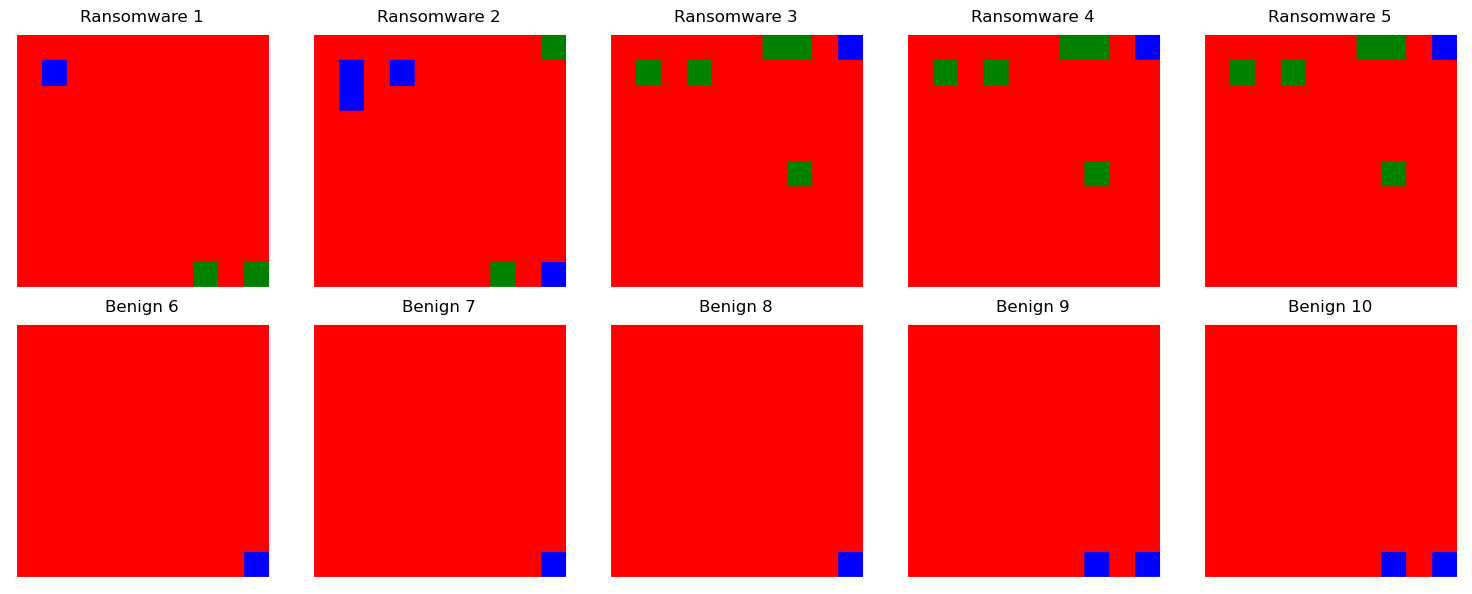

In [8]:
fig, ax = plt.subplots(2, n_r, figsize=(3 * n_r, 6))
for i in range(n_r):
    ax[0, i].imshow(mpimg.imread(f"images/R/{i+1}.png"))
    ax[0, i].set_title(f"Ransomware {i+1}")
    ax[0, i].axis("off")
    ax[1, i].imshow(mpimg.imread(f"images/B/{n_r+i+1}.png"))
    ax[1, i].set_title(f"Benign {n_r+i+1}")
    ax[1, i].axis("off")
plt.tight_layout()
plt.show()

In [9]:
!pip install tensorflow scikit-learn

In [10]:
import os, numpy as np
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0, InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input as inc_pre
from sklearn.model_selection import StratifiedKFold

print("TensorFlow:", tf.__version__)
print("Current folder:", os.getcwd())
print("images folders exist?", os.path.exists("images/R"), os.path.exists("images/B"))

TensorFlow: 2.21.0
Current folder: C:\Users\Sumai\TL-RL-FusionNet-Dataset-master
images folders exist? True True


In [11]:
IMG_DIR = "images"
WEIGHTS = "imagenet"

def load_folder(folder, label):
    X, y = [], []
    names = sorted(os.listdir(f"{IMG_DIR}/{folder}"), key=lambda s: int(s.split(".")[0]))
    for name in names:
        img = tf.keras.utils.load_img(f"{IMG_DIR}/{folder}/{name}", target_size=(224, 224))
        X.append(tf.keras.utils.img_to_array(img))
        y.append(label)
    return X, y

Xr, yr = load_folder("R", 1)
Xb, yb = load_folder("B", 0)
images = np.array(Xr + Xb, dtype="float32")
labels = np.array(yr + yb)
print("Images:", images.shape)
print("Labels:", labels.tolist())

Images: (10, 224, 224, 3)
Labels: [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]


In [12]:
eff = EfficientNetB0(include_top=False, weights=WEIGHTS, pooling="avg", input_shape=(224, 224, 3))
inc = InceptionV3(include_top=False, weights=WEIGHTS, pooling="avg", input_shape=(224, 224, 3))
eff.trainable = False
inc.trainable = False

emb_eff = eff.predict(images.copy(), verbose=0)
emb_inc = inc.predict(inc_pre(images.copy()), verbose=0)
features = np.concatenate([emb_eff, emb_inc], axis=1)

print("EfficientNetB0:", emb_eff.shape)
print("InceptionV3:", emb_inc.shape)
print("Combined:", features.shape)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 30s 0us/step
EfficientNetB0: (10, 1280)
InceptionV3: (10, 2048)
Combined: (10, 3328)


In [13]:
EPOCHS, BATCH, LR = 25, 32, 1e-3

def build_residual_mlp(input_dim=3328):
    inp = layers.Input(shape=(input_dim,))
    h = layers.Dense(1024, activation="relu")(inp)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(0.3)(h)
    for _ in range(2):
        r = h
        x = layers.Dense(256, activation="relu")(h)
        x = layers.BatchNormalization()(x)
        x = layers.Dense(1024)(x)
        h = layers.Activation("relu")(layers.Add()([x, r]))
        h = layers.Dropout(0.2)(h)
    out = layers.Dense(2, activation="softmax")(h)
    return models.Model(inp, out)

def train_mlp(X, y, sample_weight=None):
    n_steps = max(1, int(np.ceil(len(X) / BATCH))) * EPOCHS
    lr = tf.keras.optimizers.schedules.CosineDecay(LR, n_steps)
    m = build_residual_mlp(X.shape[1])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
              metrics=["accuracy"])
    m.fit(X, tf.keras.utils.to_categorical(y, 2), sample_weight=sample_weight,
          epochs=EPOCHS, batch_size=BATCH, verbose=0)
    return m

print("Parameters:", build_residual_mlp().count_params())

Parameters: 4468226


In [14]:
ACTIONS = np.array([0.25, 0.50, 1.00, 1.25, 1.50])
ALPHA, EPSILON = 0.1, 0.2

def rl_sample_weights(X_tr, y_tr, rng):
    n = len(X_tr)
    Q = np.zeros((n, len(ACTIONS)))
    explore = rng.random(n) < EPSILON
    a = np.where(explore, rng.integers(0, len(ACTIONS), n), Q.argmax(axis=1))
    probe = train_mlp(X_tr, y_tr, sample_weight=ACTIONS[a])
    pred = probe.predict(X_tr, verbose=0).argmax(axis=1)
    reward = (pred == y_tr).astype(float)
    Q[np.arange(n), a] += ALPHA * (reward - Q[np.arange(n), a])
    final = np.where(Q.max(axis=1) > 0, ACTIONS[Q.argmax(axis=1)], 1.00)
    return final

print("RL function ready")

RL function ready


In [15]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rng = np.random.default_rng(42)
acc_plain, acc_rl = [], []

for fold, (tr, te) in enumerate(skf.split(features, labels), 1):
    X_tr, y_tr = features[tr], labels[tr]
    X_te, y_te = features[te], labels[te]

    m0 = train_mlp(X_tr, y_tr)
    a0 = (m0.predict(X_te, verbose=0).argmax(axis=1) == y_te).mean()

    w = rl_sample_weights(X_tr, y_tr, rng)
    m1 = train_mlp(X_tr, y_tr, sample_weight=w)
    a1 = (m1.predict(X_te, verbose=0).argmax(axis=1) == y_te).mean()

    acc_plain.append(a0)
    acc_rl.append(a1)
    print(f"Fold {fold}: without RL = {a0:.2f} | with RL = {a1:.2f} | test samples = {len(te)}")

print(f"\nMean: without RL = {np.mean(acc_plain):.2f} | with RL = {np.mean(acc_rl):.2f}")

Fold 1: without RL = 0.50 | with RL = 0.50 | test samples = 2
Fold 2: without RL = 0.50 | with RL = 0.50 | test samples = 2
Fold 3: without RL = 0.50 | with RL = 0.50 | test samples = 2
Fold 4: without RL = 1.00 | with RL = 1.00 | test samples = 2
Fold 5: without RL = 0.50 | with RL = 0.50 | test samples = 2

Mean: without RL = 0.60 | with RL = 0.60
